## SWIGGY SALES ANALYSIS

#### Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### Import Data

In [4]:
df = pd.read_excel('C:/Users/Naras/Downloads/Swiggy Raw Data Excel.xlsx')

In [5]:
df.head()

,State,City,Order Date,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count
0,Karnataka,Bengaluru,2025-06-29,Anand Sweets & Savouries,Rajarajeshwari Nagar,Snack,Butter Murukku-200gm,133.9,4.0,0
1,Karnataka,Bengaluru,2025-04-03,Srinidhi Sagar Deluxe,Kengeri,Recommended,Badam Milk,52.0,4.5,25
2,Karnataka,Bengaluru,2025-01-15,Srinidhi Sagar Deluxe,Kengeri,Recommended,Chow Chow Bath,117.0,4.7,48
3,Karnataka,Bengaluru,2025-04-17,Srinidhi Sagar Deluxe,Kengeri,Recommended,Kesari Bath,65.0,4.6,65
4,Karnataka,Bengaluru,2025-03-13,Srinidhi Sagar Deluxe,Kengeri,Recommended,Mix Raitha,130.0,4.0,0


In [6]:
df.tail()

,State,City,Order Date,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count
197425,Sikkim,Gangtok,2025-01-25,Mama's Kitchen,Gangtok,Momos,Soya cheese chilli momo ...,112.0,4.4,0
197426,Sikkim,Gangtok,2025-07-02,Mama's Kitchen,Gangtok,Momos,Kurkure momo fried ...,140.0,4.4,0
197427,Sikkim,Gangtok,2025-03-25,Mama's Kitchen,Gangtok,Momos,Chilli cheese momo,126.0,4.4,0
197428,Sikkim,Gangtok,2025-03-26,Mama's Kitchen,Gangtok,Momos,Veg Momos (8 Pc),85.0,4.4,0
197429,Sikkim,Gangtok,2025-03-27,Mama's Kitchen,Gangtok,Momos,Soya Momo,100.0,4.4,0


#### Meta Data

In [7]:
print("No of Rows:",df.shape[0])

No of Rows: 197430


In [8]:
print("No of Fields:",df.shape[1])

No of Fields: 10


In [9]:
df.info

<bound method DataFrame.info of             State       City Order Date           Restaurant Name  \
0       Karnataka  Bengaluru 2025-06-29  Anand Sweets & Savouries   
1       Karnataka  Bengaluru 2025-04-03     Srinidhi Sagar Deluxe   
2       Karnataka  Bengaluru 2025-01-15     Srinidhi Sagar Deluxe   
3       Karnataka  Bengaluru 2025-04-17     Srinidhi Sagar Deluxe   
4       Karnataka  Bengaluru 2025-03-13     Srinidhi Sagar Deluxe   
...           ...        ...        ...                       ...   
197425     Sikkim    Gangtok 2025-01-25            Mama's Kitchen   
197426     Sikkim    Gangtok 2025-07-02            Mama's Kitchen   
197427     Sikkim    Gangtok 2025-03-25            Mama's Kitchen   
197428     Sikkim    Gangtok 2025-03-26            Mama's Kitchen   
197429     Sikkim    Gangtok 2025-03-27            Mama's Kitchen   

                    Location     Category  \
0       Rajarajeshwari Nagar        Snack   
1                    Kengeri  Recommended   
2   

#### Data Types

In [10]:
df.dtypes

State                         str
City                          str
Order Date         datetime64[us]
Restaurant Name               str
Location                      str
Category                      str
Dish Name                     str
Price (INR)               float64
Rating                    float64
Rating Count                int64
dtype: object

In [11]:
df.describe()

,Order Date,Price (INR),Rating,Rating Count
count,197430,197430.000000,197430.000000,197430.000000
mean,2025-05-01 19:41:20.996809,268.512920,4.341582,28.321805
min,2025-01-01 00:00:00,0.950000,1.500000,0.000000
25%,2025-03-01 00:00:00,139.000000,4.300000,0.000000
50%,2025-05-02 00:00:00,229.000000,4.400000,2.000000
75%,2025-07-01 00:00:00,329.000000,4.500000,15.000000
max,2025-08-31 00:00:00,8000.000000,5.000000,999.000000
std,NaN,219.338363,0.422585,87.542593


## KPI's

##### Total Sales

In [13]:
total_sales = df["Price (INR)"].sum()
print("Total Sales (INR):",round(total_sales,2))

Total Sales (INR): 53012505.77


##### Average Rating

In [14]:
average_rating = df["Rating"].mean()
print("Average Rating:",round(average_rating,2))

Average Rating: 4.34


##### Average Order Value

In [17]:
avg_order_value= df["Price (INR)"].mean()
print("Avg Order Value:",round(avg_order_value,2))

Avg Order Value: 268.51


##### Ratings Count

In [19]:
ratings_count= df["Rating Count"].sum()
print("Ratings Count:",round(ratings_count,2))

Ratings Count: 5591574


##### Total Orders

In [20]:
total_orders = len(df)
print("Total Orders:",round(total_orders,2))

Total Orders: 197430


### CHARTS  Design

##### Monthly Sales Trend

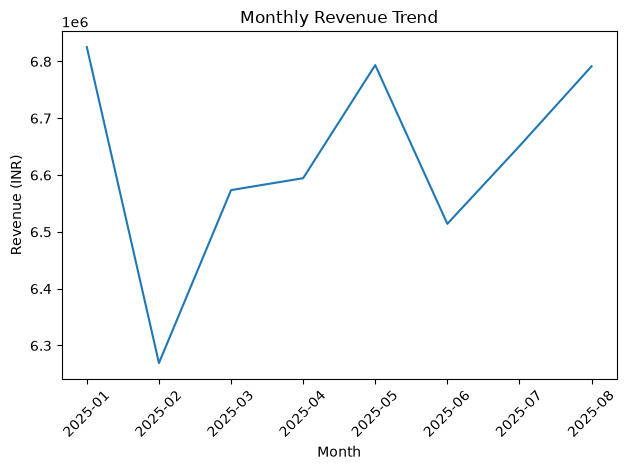

In [22]:
df["Order Date"] =pd.to_datetime(df["Order Date"])
df["YearMonth"] = df["Order Date"].dt.to_period("M").astype(str)
monthly_revenue = df.groupby("YearMonth")["Price (INR)"].sum().reset_index()
plt.figure()
plt.plot(monthly_revenue["YearMonth"],monthly_revenue["Price (INR)"])
plt.xticks(rotation=45)
plt.xlabel("Month")
plt.ylabel("Revenue (INR)")
plt.title("Monthly Revenue Trend")
plt.tight_layout()
plt.show()

##### Daily Sales Trend

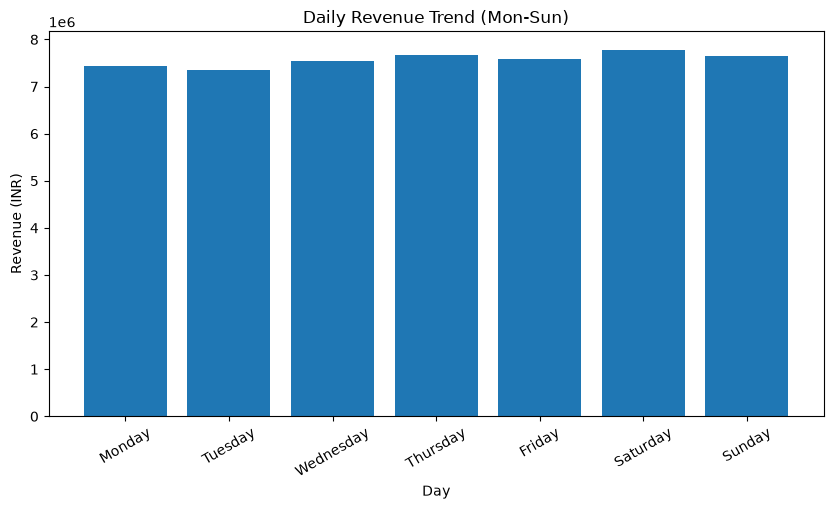

In [23]:
df["DayName"] = pd.to_datetime(df["Order Date"]).dt.day_name()
daily_revenue = (
    df.groupby("DayName")["Price (INR)"]
    .sum()
    .reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
)
plt.figure(figsize=(10,5))
plt.bar(daily_revenue.index,daily_revenue.values)
plt.title("Daily Revenue Trend (Mon-Sun)")
plt.xlabel("Day")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=30)
plt.show()

##### Total Sales by Food Type (Veg vs Non-Veg)

In [24]:
non_veg_keywords = [
    "chicken","egg","fish","mutton",
    "prawn","biryani","kabab","kebab",
    "non-veg","non veg"
]
df["Food Category"] = np.where(
    df["Dish Name"].str.lower().str.contains("|".join(non_veg_keywords),na=False),
    "Non-veg",
    "veg"
)

In [25]:
food_revenue = (
    df.groupby("Food Category")["Price (INR)"]
    .sum()
    .reset_index()
)

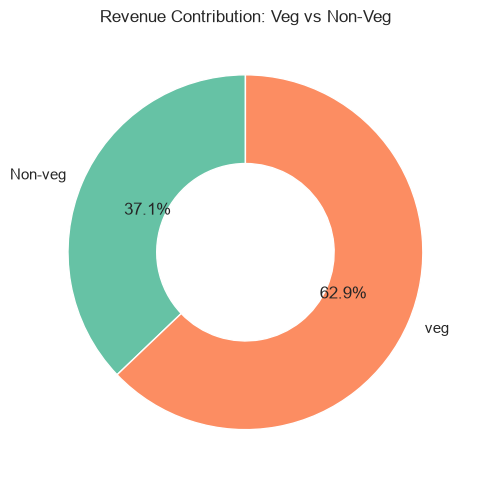

In [28]:
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(7, 5))

ax.pie(
    food_revenue["Price (INR)"],
    labels=food_revenue["Food Category"],
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2"),
    wedgeprops=dict(width=0.5, edgecolor="white")
)

ax.set_title("Revenue Contribution: Veg vs Non-Veg")

plt.tight_layout()
plt.show()

##### Total Sales by State

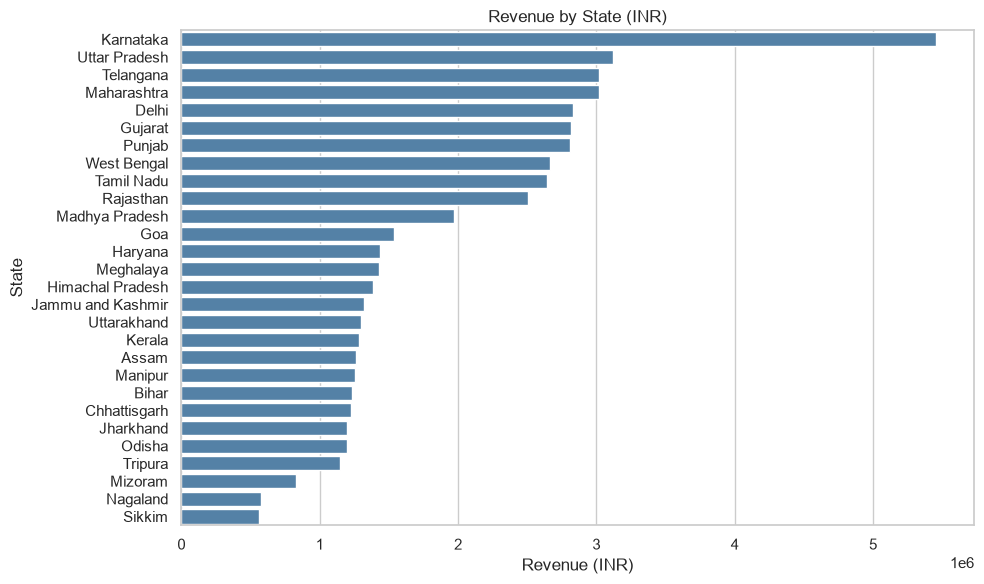

In [29]:
state_revenue = (
    df.groupby("State", as_index=False)["Price (INR)"]
    .sum()
    .sort_values("Price (INR)", ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=state_revenue,
    x="Price (INR)",
    y="State",
    color="steelblue"
)

plt.title("Revenue by State (INR)")
plt.xlabel("Revenue (INR)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

##### Quarterly Performance Summary

In [30]:
df["Order_Date"] = pd.to_datetime(df["Order Date"])
df["Quarter"] = df["Order_Date"].dt.to_period("Q").astype(str)
quartely_summary = (
    df.groupby("Quarter",as_index=False)
    .agg(
        Total_Sales=("Price (INR)","sum"),
        Avg_Rating=("Rating","mean"),
        Total_Orders=("Order_Date","count")
    )
    .sort_values("Quarter")
)
quartely_summary["Total_Sales"]=quartely_summary["Total_Sales"].round(0)
quartely_summary["Avg_Rating"]=quartely_summary["Avg_Rating"].round(2)
quartely_summary

,Quarter,Total_Sales,Avg_Rating,Total_Orders
0,2025Q1,19667822.0,4.34,73096
1,2025Q2,19902257.0,4.34,74163
2,2025Q3,13442427.0,4.34,50171


##### Top 5 Cities by Sales

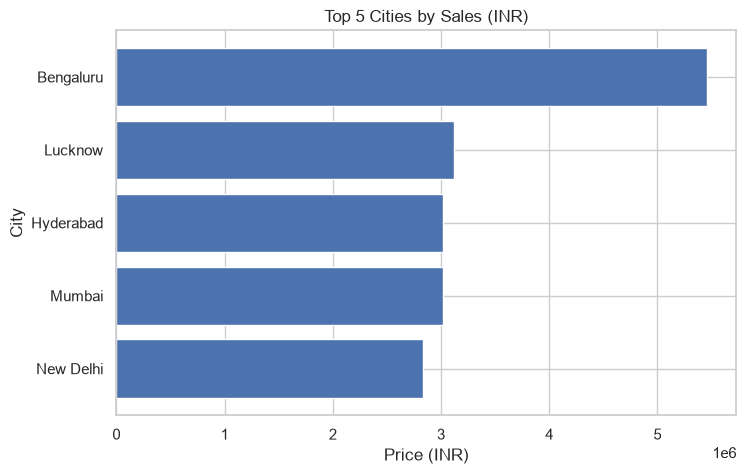

In [33]:
top_5_cities = (
    df.groupby("City")["Price (INR)"]
    .sum()
    .nlargest(5)
    .sort_values()
    .reset_index()
)
plt.figure(figsize=(8, 5))

plt.barh(
    top_5_cities["City"],
    top_5_cities["Price (INR)"],
)

plt.title("Top 5 Cities by Sales (INR)")
plt.xlabel("Price (INR)")
plt.ylabel("City")

plt.show()